# steqpy tutorial: JMA catalogue to declustering results

Ingest a catalogue, choose the magnitude cutoff, fit, then get the figures and the JSON/text outputs. Uses the JMA M ≥ 4.5 example (`data/jma/alljpM45.etas`, Zhuang's format) and its study polygon. The fit takes about 30 s on 10 threads.

**Setup:** Python 3.10+ with `pip install numpy numba matplotlib jupyter` (or `pip install -e .[plot]` from the repo root, plus Jupyter). Open this notebook from the `notebooks/` folder and run the cells in order. Results are identical at any thread count; other numpy/numba versions or CPUs can differ in the last digits (made with Python 3.12, numpy 2.5.4, numba 0.68.1).

In [1]:
import os
import sys
sys.path.insert(0, '../src')          # steqpy from this repo (not installed)
import numpy as np
import matplotlib.pyplot as plt
from steqpy import EventCatalog, StochasticDeclustering

## 1. Ingest

`EventCatalog` holds the events as read: longitude, latitude, time, magnitude, depth. Other ways in: `EventCatalog.from_csv('my.csv')` (header names like `time, longitude, latitude, magnitude`, times in UTC) or `EventCatalog.from_arrays(lon, lat, time, mag)`.

The JMA file stores time as days since its first event, so we give that event's date as `t0` to get real dates (its hour is not in the file, so dates are good to a day).

In [2]:
events = EventCatalog.from_etas('../data/jma/alljpM45.etas', t0='1926-01-08')
print(len(events), 'events,', events.t0, 'to', events.t0 + np.timedelta64(int(events.t.max()), 'D'))
print('magnitudes', events.mag.min(), 'to', events.mag.max())

13724 events, 1926-01-08T00:00:00.000 to 2007-12-29T00:00:00.000
magnitudes 4.5 to 8.2


## 2. Magnitude cutoff

Fit at or above the magnitude of completeness Mc: below it, missing small events look like clustering and the fit goes wrong (p < 1, almost everything an aftershock). Four methods, over the target window used below (from day 10000, i.e. 1953):

In [3]:
for method in ('maxc', 'gft', 'mbs', 'cv'):
    print(f'{method:5s} Mc = {events.completeness(method, start=10000.0)}')

maxc  Mc = 4.7
gft   Mc = 4.5
mbs   Mc = 5.0
cv    Mc = 4.9


The file only contains M ≥ 4.5, so the methods land at or a little above that edge (4.5 to 5.0 here). MAXC, MBS and CV above 4.5 hint that the earliest years miss some M4.5-4.6 events. We use 4.5 to match Zhuang's example; a stricter choice (4.7 to 5.0, or a later start) is safer for a new study.

## 3. Fit

The study area is a polygon of `[lon, lat]` corners. Target events are inside it and in the window `[t_start, t_end]`; earlier events and events outside it still count as possible triggers. Times can be dates (with `t0` set) or days since `t0`.

In [4]:
polygon = np.loadtxt('../configs/jma_polygon.txt')      # [[lon, lat], ...]
sd = StochasticDeclustering.from_catalog(events, polygon, t_start=10000.0, t_end=23376.0,
                                         mag_min=4.5, t_min=0.0,
                                         threads=min(10, os.cpu_count()))   # same result at any count
result = sd.fit()
print('converged:', result.converged, '| usable:', result.checks['usable'],
      '| warnings:', result.checks['warnings'] or 'none')
result.params

converged: True | usable: True | warnings: none


ETASParams(mu=0.5496958931517407, A=0.16800945363294784, c=0.0293173291487933, alpha=1.6465773402595572, p=1.1525534611376294, D=0.001851477977144713, q=1.949717548199851, gamma=1.0512161797401927)

`checks['usable']` is the website's rule: the fit passed its checks and p, q > 1. `checks['warnings']` lists signs of a fit that does not describe the data (p or q ≤ 1, almost no background, converged only on the last allowed iteration).

## 4. Results

Counts of target events by their chance of being an aftershock:

In [5]:
s = result.summary()
{k: s[k] for k in ('n_targets', 'certain_background', 'uncertain', 'certain_aftershock',
                   'expected_background', 'expected_aftershocks')}

{'n_targets': 4658,
 'certain_background': 1355,
 'uncertain': 1618,
 'certain_aftershock': 1685,
 'expected_background': 2349.244367798968,
 'expected_aftershocks': 2308.755632201032}

### Figures

Everything on one figure:

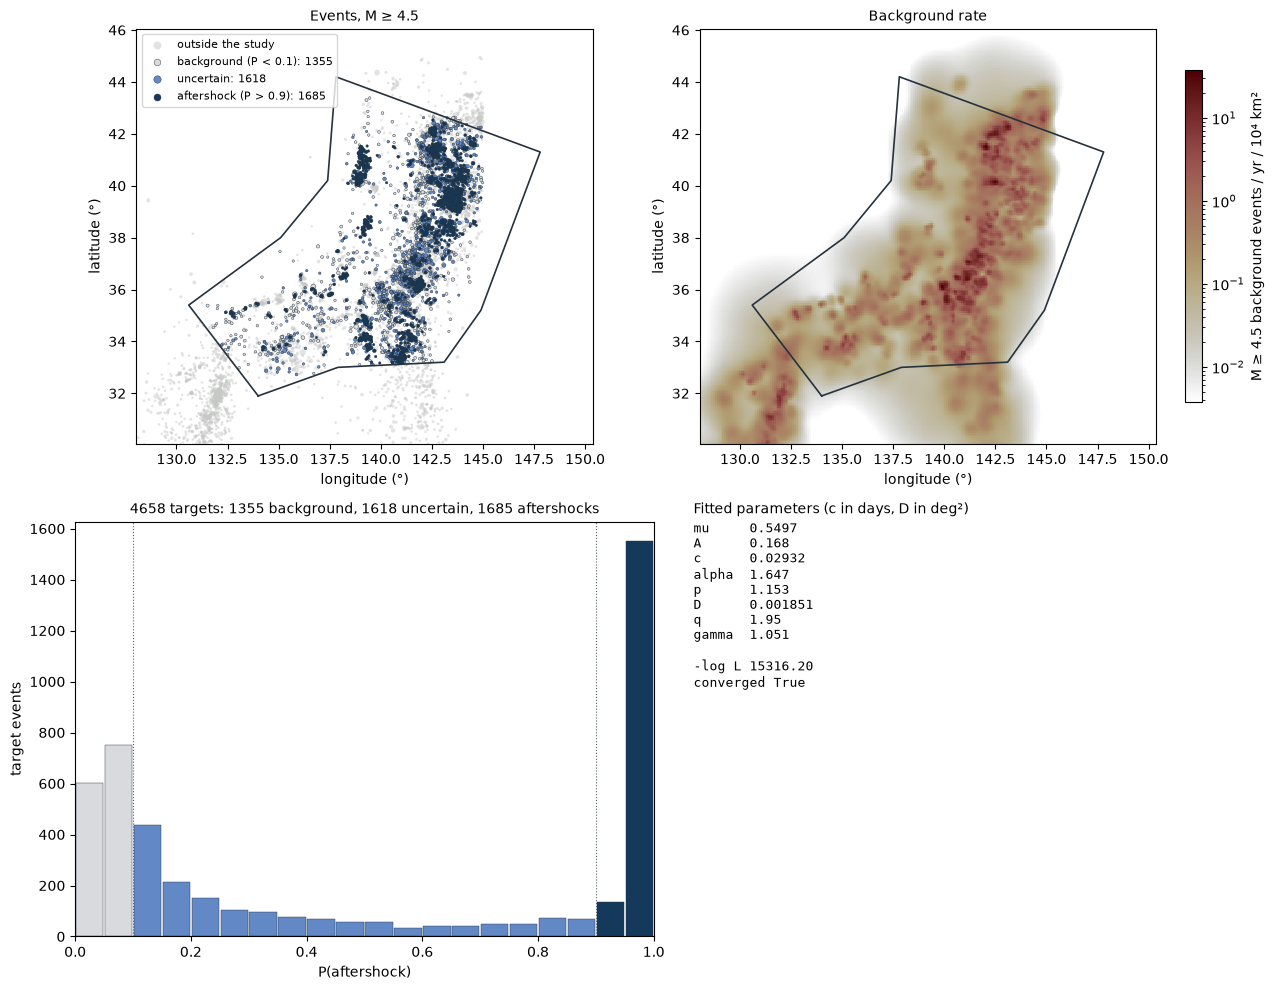

In [6]:
fig = result.plot_summary()

Or one view at a time, each into its own axes (pass `ax=` to draw into yours):

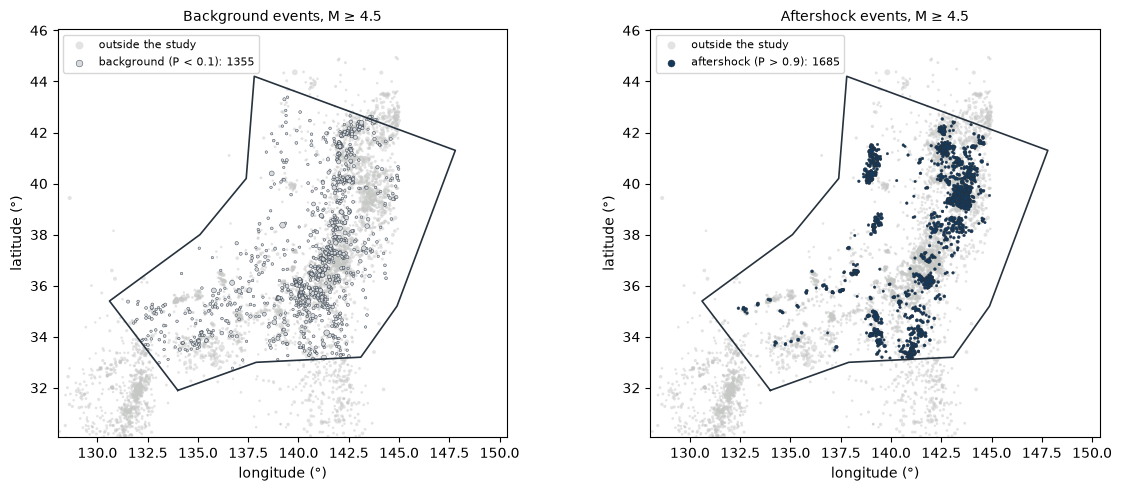

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 5))
result.plot_events('background', ax=a)
result.plot_events('aftershock', ax=b)
fig.tight_layout()

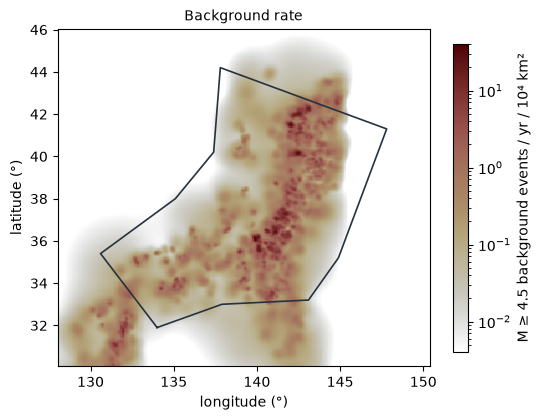

In [8]:
ax = result.plot_background_rate(n=300)

### Per-event probabilities

`final_background_prob[i]` is the chance that event *i* is a background event. A declustered catalogue is one random draw from these (`sample_background`); different seeds give different, equally valid catalogues.

In [9]:
phi = result.final_background_prob
target = result.ind == 1
keep = result.sample_background(seed=1) & target
print(f'{keep.sum()} of {target.sum()} target events kept as background in this draw')

2352 of 4658 target events kept as background in this draw


### JSON and files

`to_dict()` is what the website reads (fit status, parameters, summary, every event with its probability, polygon, projection). `write_outputs` writes `result.json`, `params.txt`, `probs.dat` and a `config.toml` (plus the catalogue) that reruns this exact fit.

In [10]:
d = result.to_dict()
print(list(d))
print(d['fit'])

['steqpy_version', 'fit', 'params', 'units', 'errors', 'summary', 'events', 'region', 'seeds', 'projection', 'background']
{'valid': True, 'failed': [], 'warnings': [], 'converged': True, 'neg_loglik': 15316.196236566266, 'aic': 30648.39247313253, 'likelihood_calls': 78, 'n_events': 10071, 'n_targets': 4658, 'usable': True, 'background_share': 0.5043461502359313}


In [11]:
from pathlib import Path
out = Path('../build/tutorial_jma')
result.write_outputs(out)
sorted(p.name for p in out.iterdir())

['catalogue.etas', 'config.toml', 'params.txt', 'probs.dat', 'result.json']

Rerun later from the files alone: `StochasticDeclustering.from_config('../build/tutorial_jma/config.toml').fit()`, or from the command line: `python -m steqpy build/tutorial_jma/config.toml --out results/again`.